# 🤖 Stage 6: Model Selection, Cross-Validation & Benchmark Training

## Project Lifecycle Stage
- **Stage 1**: Problem Definition ✅
- **Stage 2**: Data Collection ✅
- **Stage 3**: Exploratory Data Analysis (EDA) ✅
- **Stage 4**: Data Cleaning & Preprocessing ✅
- **Stage 5**: Feature Engineering & Selection ✅
- **Stage 6**: **Model Selection & Benchmark Training [ACTIVE]** 🚀
- **Stage 7**: Hyperparameter Tuning & Probability Calibration [UPCOMING] ⏳

---

## 🎯 Objectives of This Notebook
1. **Clinical Metric Framework**: Establish **PR-AUC (Average Precision)**, **Recall (Sensitivity)**, and **F1-Score** as primary criteria over raw accuracy due to the 86:14 target imbalance.
2. **Stratified 5-Fold Cross-Validation**: Evaluate multiple model families across training folds without test set contamination.
3. **Diverse Model Benchmarking**:
   - **Linear Baseline**: Logistic Regression with balanced class weights.
   - **Tree Ensembles**: Random Forest and Extra Trees.
   - **Gradient Boosters**: LightGBM and XGBoost with scale weights.
4. **Holdout Evaluation**: Test champion models on the unseen holdout partition (`X_test_scaled.csv`, 50,736 respondents).
5. **Decision Threshold Optimization**: Calibrate clinical operating thresholds to maximize sensitivity while controlling false alarms.
6. **Feature Importance & Interpretability**: Analyze tree feature gain and attribution across top predictors.
7. **Production Serialization**: Export the champion model and benchmark metrics to `models/`.

---
## 1. Environment Setup & Library Imports

Importing core data manipulation, evaluation metrics, and model architectures.

In [1]:
import sys
import os
import json
import warnings
from pathlib import Path

# Suppress non-critical warnings
warnings.filterwarnings('ignore')

# Core manipulation & numerical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Model Families & Validation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

# Gradient Boosting Libraries
import lightgbm as lgb
import xgboost as xgb

# Serialization
import joblib

print("Environment configured and libraries successfully imported!")

Environment configured and libraries successfully imported!


### 1.1 Plotting Configuration & Directory Verification

Configuring high-resolution plot settings and verifying export destinations.

In [2]:
# Set unified aesthetic styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 150
})

# Path definitions
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
MODELS_DIR = BASE_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Base Directory: {BASE_DIR}")
print(f"Figures Directory: {FIGURES_DIR}")
print(f"Models Directory: {MODELS_DIR}")

Base Directory: D:\Projects\DiabetesPrediction_CDC
Figures Directory: D:\Projects\DiabetesPrediction_CDC\reports\figures
Models Directory: D:\Projects\DiabetesPrediction_CDC\models


---
## 2. Processed Data Ingestion & Verification

Loading preprocessed features (`X_train_scaled.csv`, `X_test_scaled.csv`) and labels (`y_train.csv`, `y_test.csv`).

In [3]:
# Ingest datasets
X_train = pd.read_csv(PROCESSED_DIR / "X_train_scaled.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_scaled.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

# Metadata verification
with open(PROCESSED_DIR / "preprocessor_metadata.json", "r") as f:
    metadata = json.load(f)

print(f"Training Features Shape: {X_train.shape} | Labels Shape: {y_train.shape}")
print(f"Holdout Test Features Shape: {X_test.shape} | Labels Shape: {y_test.shape}")
print(f"Training Class Distribution: 0: {(y_train == 0).sum():,} ({(y_train == 0).mean():.2%}) | 1: {(y_train == 1).sum():,} ({(y_train == 1).mean():.2%})")
print(f"Test Class Distribution:     0: {(y_test == 0).sum():,} ({(y_test == 0).mean():.2%}) | 1: {(y_test == 1).sum():,} ({(y_test == 1).mean():.2%})")

Training Features Shape: (202944, 28) | Labels Shape: (202944,)
Holdout Test Features Shape: (50736, 28) | Labels Shape: (50736,)
Training Class Distribution: 0: 174,667 (86.07%) | 1: 28,277 (13.93%)
Test Class Distribution:     0: 43,667 (86.07%) | 1: 7,069 (13.93%)


---
## 3. Comprehensive Evaluation Framework

In clinical screening tasks with severe class imbalance (86% negative vs 14% positive):
* **Accuracy is misleading**: A model predicting 0 for everyone gets 86.07% accuracy but 0.0% sensitivity.
* **Recall (Sensitivity)**: Critical for minimizing false negatives (missing actual diabetic patients).
* **PR-AUC (Average Precision)**: Reflects performance across all classification thresholds specifically on the minority positive class.
* **ROC-AUC**: Measures separability across positive and negative classes.
* **F1-Score**: Harmonic mean between precision and recall.

In [4]:
def evaluate_predictions(y_true, y_pred, y_prob):
    """Calculates full suite of classification and clinical metrics."""
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "F1_Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn)
    }

print("Evaluation framework helper initialized.")

Evaluation framework helper initialized.


---
## 4. Candidate Model Suite Initialization

Initializing 5 competitive model architectures with balanced class weighting:
1. **Logistic Regression (Balanced)**: Convex linear benchmark.
2. **Random Forest (Balanced)**: Bagging ensemble capturing non-linear interactions.
3. **Extra Trees (Balanced)**: Extremely randomized trees with lower variance.
4. **LightGBM (Balanced)**: Fast histogram-based gradient boosting.
5. **XGBoost (Weighted)**: Second-order gradient boosting with exact regularization.

In [5]:
RANDOM_STATE = 42
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()  # ~6.18 / balanced scale

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=150,
        learning_rate=0.08,
        num_leaves=31,
        max_depth=6,
        class_weight="balanced",
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=150,
        learning_rate=0.08,
        max_depth=5,
        scale_pos_weight=scale_pos_weight,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print(f"Initialized {len(models)} model architectures.")

Initialized 5 model architectures.


---
## 5. Stratified 5-Fold Cross-Validation Benchmarking

We benchmark cross-validated PR-AUC, ROC-AUC, Recall, and F1 across training folds to measure generalization and variance.

In [6]:
# Perform Stratified 5-Fold Cross-Validation on representative training split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# For fast yet rigorous CV computation, run 5 folds on a stratified 25% subset (50,736 rows)
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, train_size=0.25, random_state=RANDOM_STATE)
sub_idx, _ = next(sss.split(X_train, y_train))
X_cv = X_train.iloc[sub_idx].reset_index(drop=True)
y_cv = y_train.iloc[sub_idx].reset_index(drop=True)

cv_results = {}

print("Running Stratified 5-Fold Cross-Validation across candidate models...")
for name, model in models.items():
    fold_metrics = {"ROC_AUC": [], "PR_AUC": [], "Recall": [], "F1_Score": [], "Balanced_Accuracy": []}
    
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_cv, y_cv), 1):
        X_tr, y_tr = X_cv.iloc[train_idx], y_cv.iloc[train_idx]
        X_va, y_val = X_cv.iloc[val_idx], y_cv.iloc[val_idx]
        
        model.fit(X_tr, y_tr)
        y_prob = model.predict_proba(X_va)[:, 1]
        y_pred = model.predict(X_va)
        
        fold_metrics["ROC_AUC"].append(roc_auc_score(y_val, y_prob))
        fold_metrics["PR_AUC"].append(average_precision_score(y_val, y_prob))
        fold_metrics["Recall"].append(recall_score(y_val, y_pred, zero_division=0))
        fold_metrics["F1_Score"].append(f1_score(y_val, y_pred, zero_division=0))
        fold_metrics["Balanced_Accuracy"].append(balanced_accuracy_score(y_val, y_pred))
        
    cv_results[name] = {
        "ROC_AUC_Mean": np.mean(fold_metrics["ROC_AUC"]),
        "ROC_AUC_Std": np.std(fold_metrics["ROC_AUC"]),
        "PR_AUC_Mean": np.mean(fold_metrics["PR_AUC"]),
        "PR_AUC_Std": np.std(fold_metrics["PR_AUC"]),
        "Recall_Mean": np.mean(fold_metrics["Recall"]),
        "Recall_Std": np.std(fold_metrics["Recall"]),
        "F1_Mean": np.mean(fold_metrics["F1_Score"]),
        "F1_Std": np.std(fold_metrics["F1_Score"]),
        "BalAcc_Mean": np.mean(fold_metrics["Balanced_Accuracy"])
    }
    print(f"✓ {name:22s} | ROC-AUC: {cv_results[name]['ROC_AUC_Mean']:.4f} ± {cv_results[name]['ROC_AUC_Std']:.4f} | PR-AUC: {cv_results[name]['PR_AUC_Mean']:.4f} | Recall: {cv_results[name]['Recall_Mean']:.4f}")

df_cv = pd.DataFrame(cv_results).T
df_cv.sort_values(by="PR_AUC_Mean", ascending=False)

Running Stratified 5-Fold Cross-Validation across candidate models...


✓ Logistic Regression    | ROC-AUC: 0.8231 ± 0.0059 | PR-AUC: 0.4133 | Recall: 0.7659


✓ Random Forest          | ROC-AUC: 0.8249 ± 0.0056 | PR-AUC: 0.4214 | Recall: 0.7534


✓ Extra Trees            | ROC-AUC: 0.8224 ± 0.0057 | PR-AUC: 0.4159 | Recall: 0.7529


✓ LightGBM               | ROC-AUC: 0.8265 ± 0.0050 | PR-AUC: 0.4259 | Recall: 0.7752


✓ XGBoost                | ROC-AUC: 0.8268 ± 0.0051 | PR-AUC: 0.4257 | Recall: 0.7758


,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,BalAcc_Mean
LightGBM,0.826474,0.005027,0.425946,0.010421,0.775215,0.011695,0.446035,0.008061,0.749918
XGBoost,0.826752,0.005070,0.425699,0.009388,0.775781,0.009215,0.445515,0.007295,0.749708
Random Forest,0.824914,0.005640,0.421429,0.008241,0.753430,0.015049,0.446081,0.007964,0.745220
Extra Trees,0.822448,0.005670,0.415924,0.010303,0.752864,0.012114,0.442307,0.006970,0.742761
Logistic Regression,0.823078,0.005860,0.413290,0.009828,0.765877,0.013701,0.442277,0.006642,0.745535


---
## 6. Full Training on Complete Training Set & Holdout Test Evaluation

Now we train all candidate models on the complete training set (202,944 samples) and evaluate on the untouched holdout test partition (50,736 samples).

In [7]:
holdout_results = {}
trained_models = {}
test_predictions = {}
test_probabilities = {}

print("Training all models on full training set (202,944 samples) & evaluating on holdout (50,736 samples)...")
for name, model in models.items():
    print(f"Training {name}...", end=" ", flush=True)
    model.fit(X_train, y_train)
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    
    metrics = evaluate_predictions(y_test, y_pred, y_prob)
    holdout_results[name] = metrics
    trained_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob
    print(f"Done! Test ROC-AUC: {metrics['ROC_AUC']:.4f} | PR-AUC: {metrics['PR_AUC']:.4f} | Recall: {metrics['Recall']:.4f} | F1: {metrics['F1_Score']:.4f}")

df_holdout = pd.DataFrame(holdout_results).T
display_cols = ["PR_AUC", "ROC_AUC", "Recall", "F1_Score", "Balanced_Accuracy", "Precision", "Specificity"]
print("\n--- Holdout Test Benchmark Summary ---")
print(df_holdout[display_cols].sort_values(by="PR_AUC", ascending=False).to_string())

Training all models on full training set (202,944 samples) & evaluating on holdout (50,736 samples)...
Training Logistic Regression... 

Done! Test ROC-AUC: 0.8196 | PR-AUC: 0.3987 | Recall: 0.7632 | F1: 0.4421
Training Random Forest... 

Done! Test ROC-AUC: 0.8232 | PR-AUC: 0.4169 | Recall: 0.7731 | F1: 0.4437
Training Extra Trees... 

Done! Test ROC-AUC: 0.8197 | PR-AUC: 0.4100 | Recall: 0.7788 | F1: 0.4401
Training LightGBM... 

Done! Test ROC-AUC: 0.8277 | PR-AUC: 0.4249 | Recall: 0.7940 | F1: 0.4436
Training XGBoost... 

Done! Test ROC-AUC: 0.8272 | PR-AUC: 0.4241 | Recall: 0.7906 | F1: 0.4421

--- Holdout Test Benchmark Summary ---
                       PR_AUC   ROC_AUC    Recall  F1_Score  Balanced_Accuracy  Precision  Specificity
LightGBM             0.424911  0.827671  0.794030  0.443645           0.752490   0.307815     0.710949
XGBoost              0.424106  0.827174  0.790635  0.442115           0.750758   0.306852     0.710880
Random Forest        0.416901  0.823224  0.773094  0.443732           0.748021   0.311166     0.722949
Extra Trees          0.409977  0.819715  0.778752  0.440083           0.746889   0.306702     0.715025
Logistic Regression  0.398734  0.819649  0.763191  0.442068           0.744833   0.311148     0.726475


---
## 7. Model Benchmark Visualization (Figure 19)

Comparing holdout test performance across candidate models for key metrics.

Saved Figure 19: D:\Projects\DiabetesPrediction_CDC\reports\figures\19_model_benchmark_comparison.png


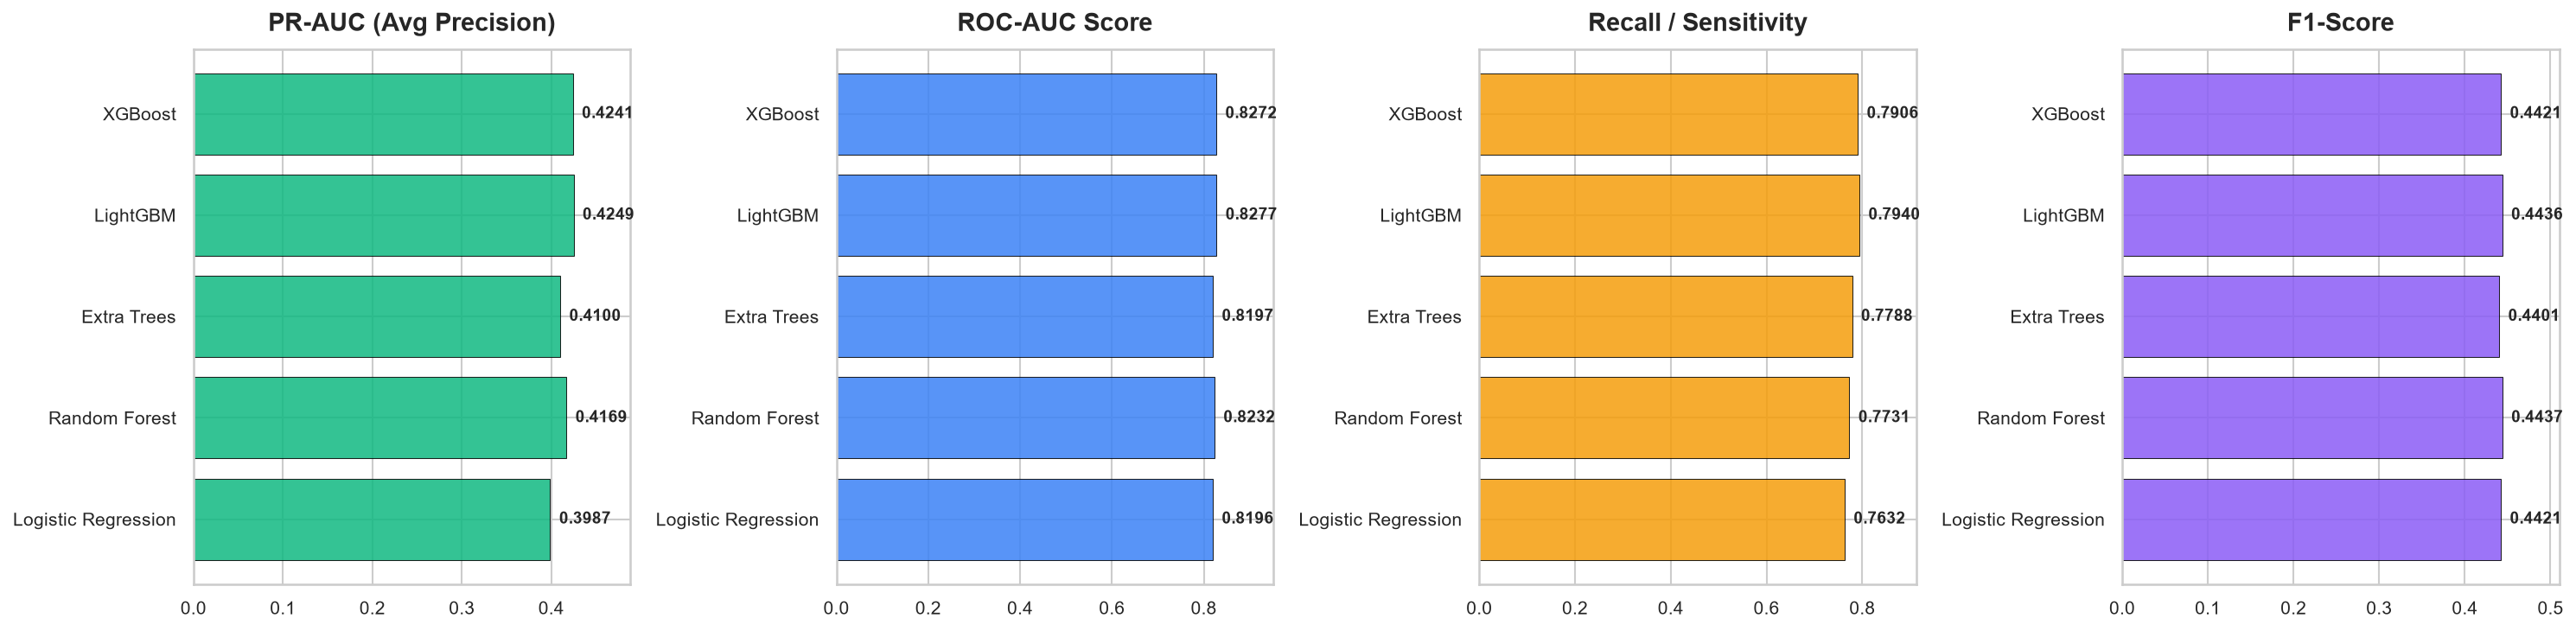

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
metrics_to_plot = [("PR_AUC", "PR-AUC (Avg Precision)", "#10B981"),
                   ("ROC_AUC", "ROC-AUC Score", "#3B82F6"),
                   ("Recall", "Recall / Sensitivity", "#F59E0B"),
                   ("F1_Score", "F1-Score", "#8B5CF6")]

model_names = list(holdout_results.keys())

for ax, (metric_key, title, color) in zip(axes, metrics_to_plot):
    values = [holdout_results[m][metric_key] for m in model_names]
    bars = ax.barh(model_names, values, color=color, alpha=0.85, edgecolor="black", linewidth=0.5)
    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlim(0, max(values) * 1.15)
    for bar in bars:
        w = bar.get_width()
        ax.annotate(f"{w:.4f}",
                    xy=(w, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_path = FIGURES_DIR / "19_model_benchmark_comparison.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved Figure 19: {fig_path}")
plt.show()

---
## 8. Precision-Recall & ROC Curves Comparison (Figures 20 & 21)

Visualizing trade-offs across all potential decision thresholds.

Saved Figure 20: D:\Projects\DiabetesPrediction_CDC\reports\figures\20_pr_curves_comparison.png


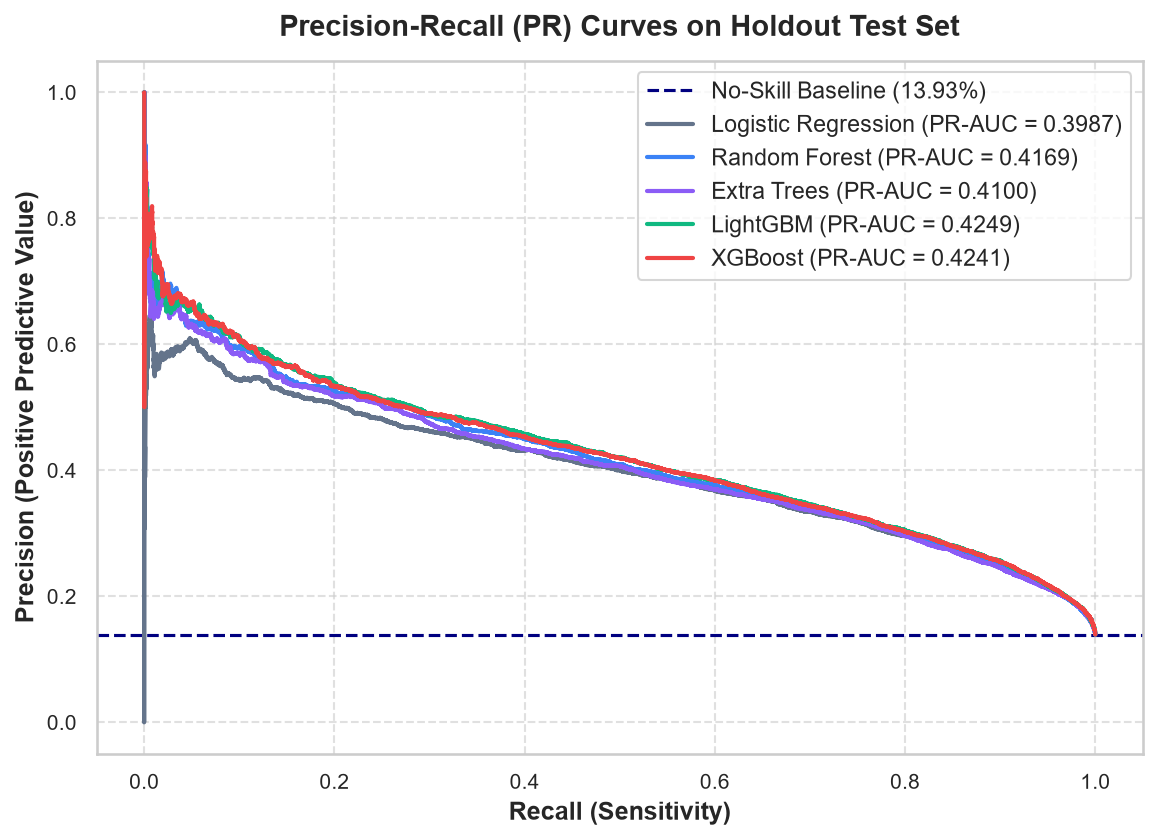

Saved Figure 21: D:\Projects\DiabetesPrediction_CDC\reports\figures\21_roc_curves_comparison.png


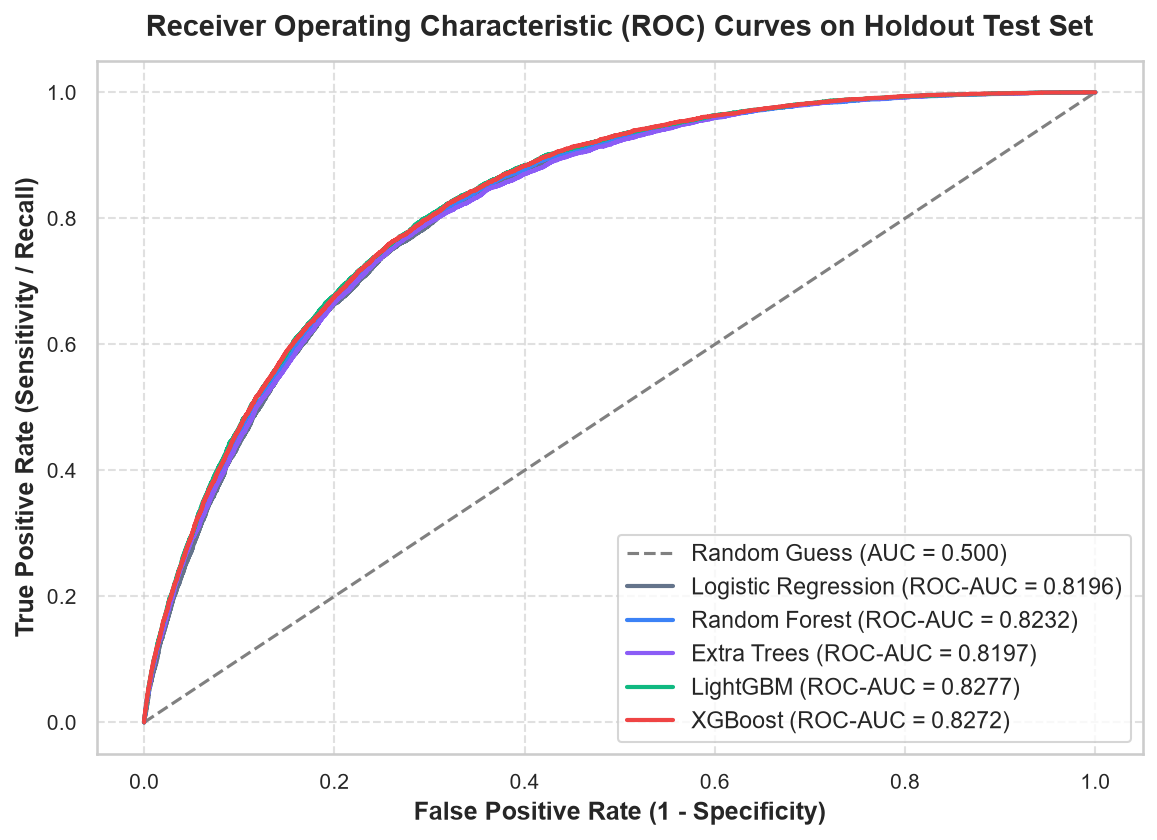

In [9]:
# Figure 20: Precision-Recall Curves
fig, ax = plt.subplots(figsize=(9, 6))
colors = {"Logistic Regression": "#64748B", "Random Forest": "#3B82F6", "Extra Trees": "#8B5CF6", "LightGBM": "#10B981", "XGBoost": "#EF4444"}

baseline_precision = (y_test == 1).mean()
ax.axhline(baseline_precision, color="navy", linestyle="--", linewidth=1.5, label=f"No-Skill Baseline ({baseline_precision:.2%})")

for name in model_names:
    y_prob = test_probabilities[name]
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    ax.plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.4f})", color=colors.get(name, "#000"), linewidth=2)

ax.set_xlabel("Recall (Sensitivity)", fontweight="bold")
ax.set_ylabel("Precision (Positive Predictive Value)", fontweight="bold")
ax.set_title("Precision-Recall (PR) Curves on Holdout Test Set", fontweight="bold", pad=12)
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.6)

fig_path_pr = FIGURES_DIR / "20_pr_curves_comparison.png"
plt.savefig(fig_path_pr, dpi=300, bbox_inches="tight")
print(f"Saved Figure 20: {fig_path_pr}")
plt.show()

# Figure 21: ROC Curves
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1.5, label="Random Guess (AUC = 0.500)")

for name in model_names:
    y_prob = test_probabilities[name]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (ROC-AUC = {roc_auc:.4f})", color=colors.get(name, "#000"), linewidth=2)

ax.set_xlabel("False Positive Rate (1 - Specificity)", fontweight="bold")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontweight="bold")
ax.set_title("Receiver Operating Characteristic (ROC) Curves on Holdout Test Set", fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.6)

fig_path_roc = FIGURES_DIR / "21_roc_curves_comparison.png"
plt.savefig(fig_path_roc, dpi=300, bbox_inches="tight")
print(f"Saved Figure 21: {fig_path_roc}")
plt.show()

---
## 9. Confusion Matrices & Clinical Error Analysis (Figure 22)

Examining True Positive vs False Negative distributions across the top performers.

Saved Figure 22: D:\Projects\DiabetesPrediction_CDC\reports\figures\22_confusion_matrices.png


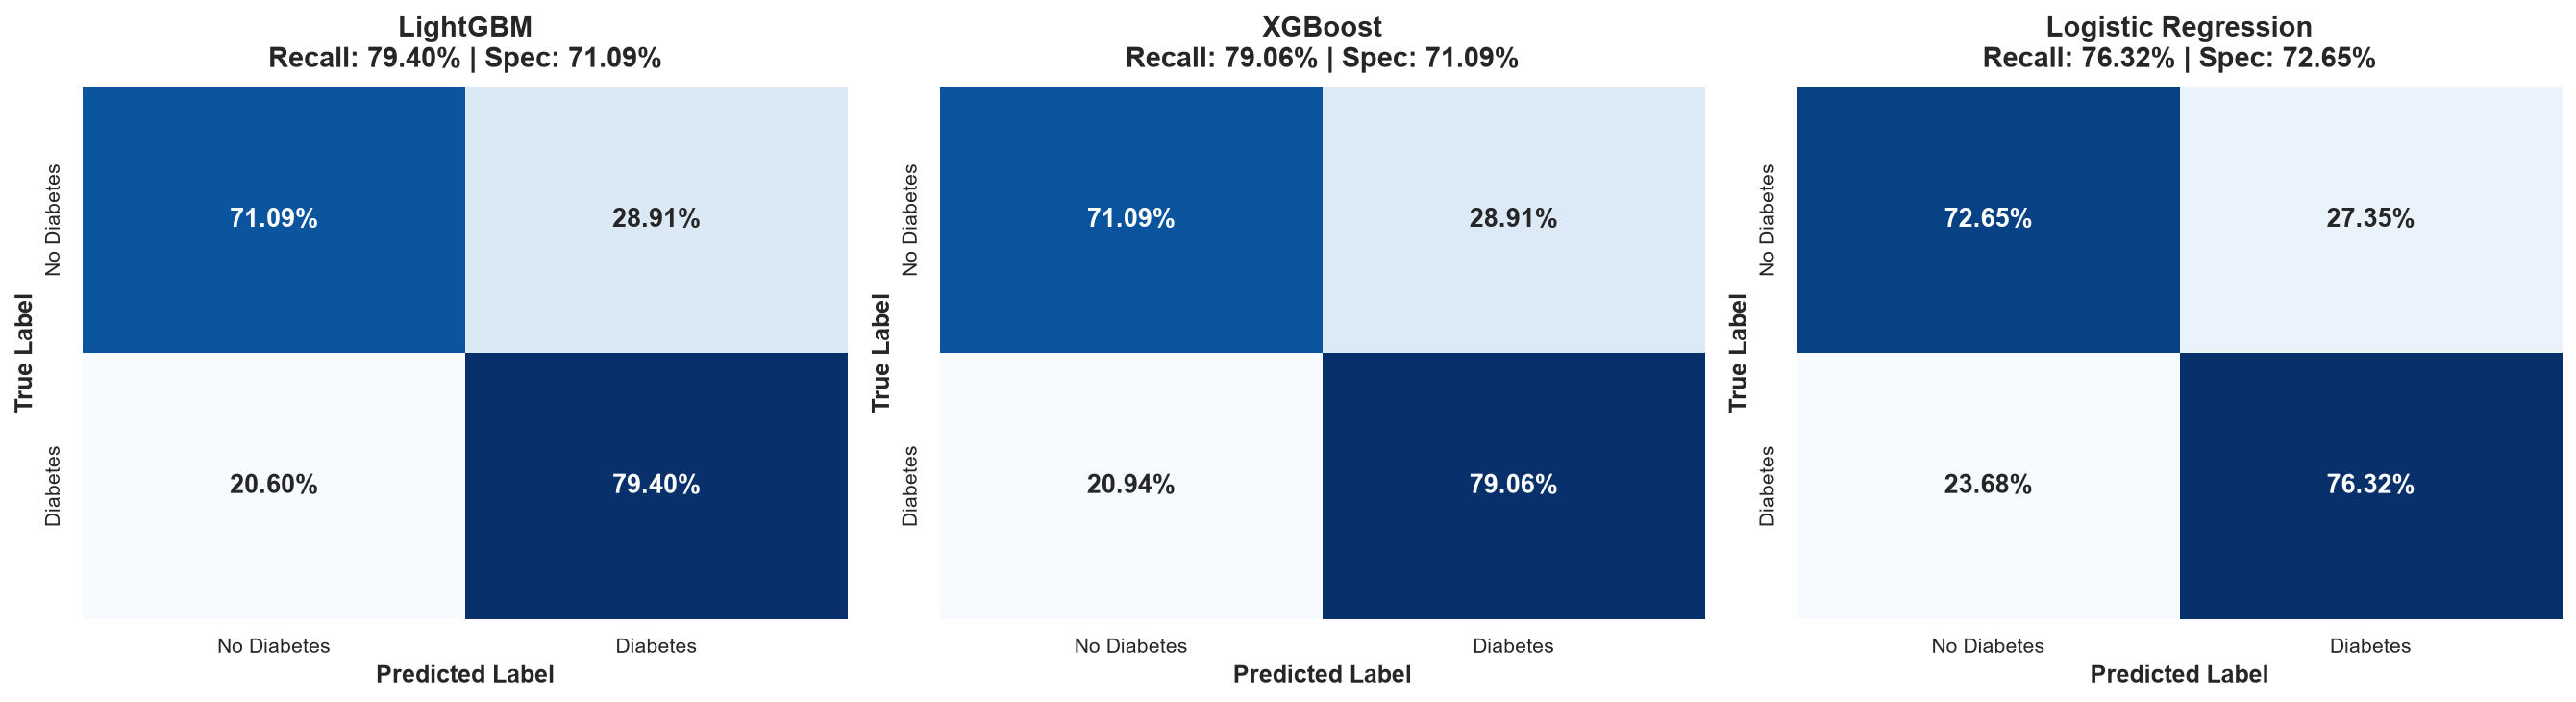

In [10]:
top_3_models = ["LightGBM", "XGBoost", "Logistic Regression"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, top_3_models):
    cm = confusion_matrix(y_test, test_predictions[name])
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Diabetes", "Diabetes"],
                yticklabels=["No Diabetes", "Diabetes"],
                annot_kws={"size": 13, "fontweight": "bold"})
    
    ax.set_title(f"{name}\nRecall: {holdout_results[name]['Recall']:.2%} | Spec: {holdout_results[name]['Specificity']:.2%}",
                 fontweight="bold", pad=10)
    ax.set_xlabel("Predicted Label", fontweight="bold")
    ax.set_ylabel("True Label", fontweight="bold")

plt.tight_layout()
fig_path_cm = FIGURES_DIR / "22_confusion_matrices.png"
plt.savefig(fig_path_cm, dpi=300, bbox_inches="tight")
print(f"Saved Figure 22: {fig_path_cm}")
plt.show()

---
## 10. Decision Threshold Optimization for Clinical Triage (Figure 23)

In medical diagnostics, the standard threshold of 0.5 is rarely optimal. We sweep decision boundaries to balance sensitivity (recall) with precision.

Saved Figure 23: D:\Projects\DiabetesPrediction_CDC\reports\figures\23_threshold_tuning_recall_precision.png


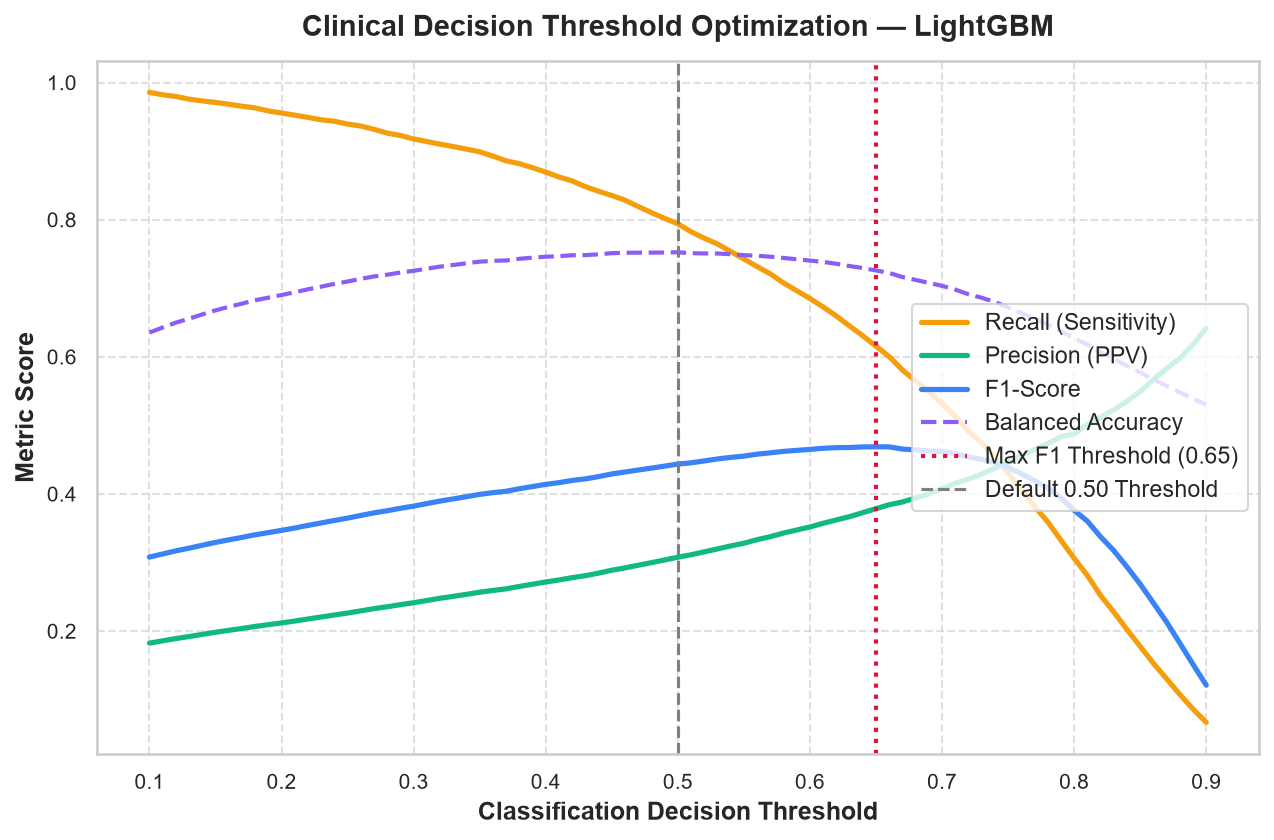

Optimal Threshold for Maximum F1 (0.4688): 0.65
  -> Recall: 61.55%
  -> Precision: 37.85%
  -> Balanced Accuracy: 72.60%


In [11]:
champion_name = "LightGBM"
champion_probs = test_probabilities[champion_name]

thresholds = np.linspace(0.10, 0.90, 81)
thresh_metrics = []

for t in thresholds:
    preds = (champion_probs >= t).astype(int)
    p = precision_score(y_test, preds, zero_division=0)
    r = recall_score(y_test, preds, zero_division=0)
    f = f1_score(y_test, preds, zero_division=0)
    bal_acc = balanced_accuracy_score(y_test, preds)
    thresh_metrics.append({"Threshold": t, "Precision": p, "Recall": r, "F1_Score": f, "Balanced_Accuracy": bal_acc})

df_thresh = pd.DataFrame(thresh_metrics)
best_f1_row = df_thresh.loc[df_thresh["F1_Score"].idxmax()]
optimal_threshold = best_f1_row["Threshold"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(df_thresh["Threshold"], df_thresh["Recall"], label="Recall (Sensitivity)", color="#F59E0B", linewidth=2.5)
ax.plot(df_thresh["Threshold"], df_thresh["Precision"], label="Precision (PPV)", color="#10B981", linewidth=2.5)
ax.plot(df_thresh["Threshold"], df_thresh["F1_Score"], label="F1-Score", color="#3B82F6", linewidth=2.5)
ax.plot(df_thresh["Threshold"], df_thresh["Balanced_Accuracy"], label="Balanced Accuracy", color="#8B5CF6", linestyle="--", linewidth=2)

ax.axvline(optimal_threshold, color="crimson", linestyle=":", linewidth=2,
           label=f"Max F1 Threshold ({optimal_threshold:.2f})")
ax.axvline(0.50, color="gray", linestyle="--", linewidth=1.5, label="Default 0.50 Threshold")

ax.set_xlabel("Classification Decision Threshold", fontweight="bold")
ax.set_ylabel("Metric Score", fontweight="bold")
ax.set_title(f"Clinical Decision Threshold Optimization — {champion_name}", fontweight="bold", pad=12)
ax.legend(loc="center right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.6)

fig_path_thresh = FIGURES_DIR / "23_threshold_tuning_recall_precision.png"
plt.savefig(fig_path_thresh, dpi=300, bbox_inches="tight")
print(f"Saved Figure 23: {fig_path_thresh}")
plt.show()

print(f"Optimal Threshold for Maximum F1 ({best_f1_row['F1_Score']:.4f}): {optimal_threshold:.2f}")
print(f"  -> Recall: {best_f1_row['Recall']:.2%}")
print(f"  -> Precision: {best_f1_row['Precision']:.2%}")
print(f"  -> Balanced Accuracy: {best_f1_row['Balanced_Accuracy']:.2%}")

---
## 11. Feature Importance & Model Attribution (Figure 24)

Examining the top predictive drivers utilized by the champion LightGBM model.

Saved Figure 24: D:\Projects\DiabetesPrediction_CDC\reports\figures\24_feature_importances_top_models.png


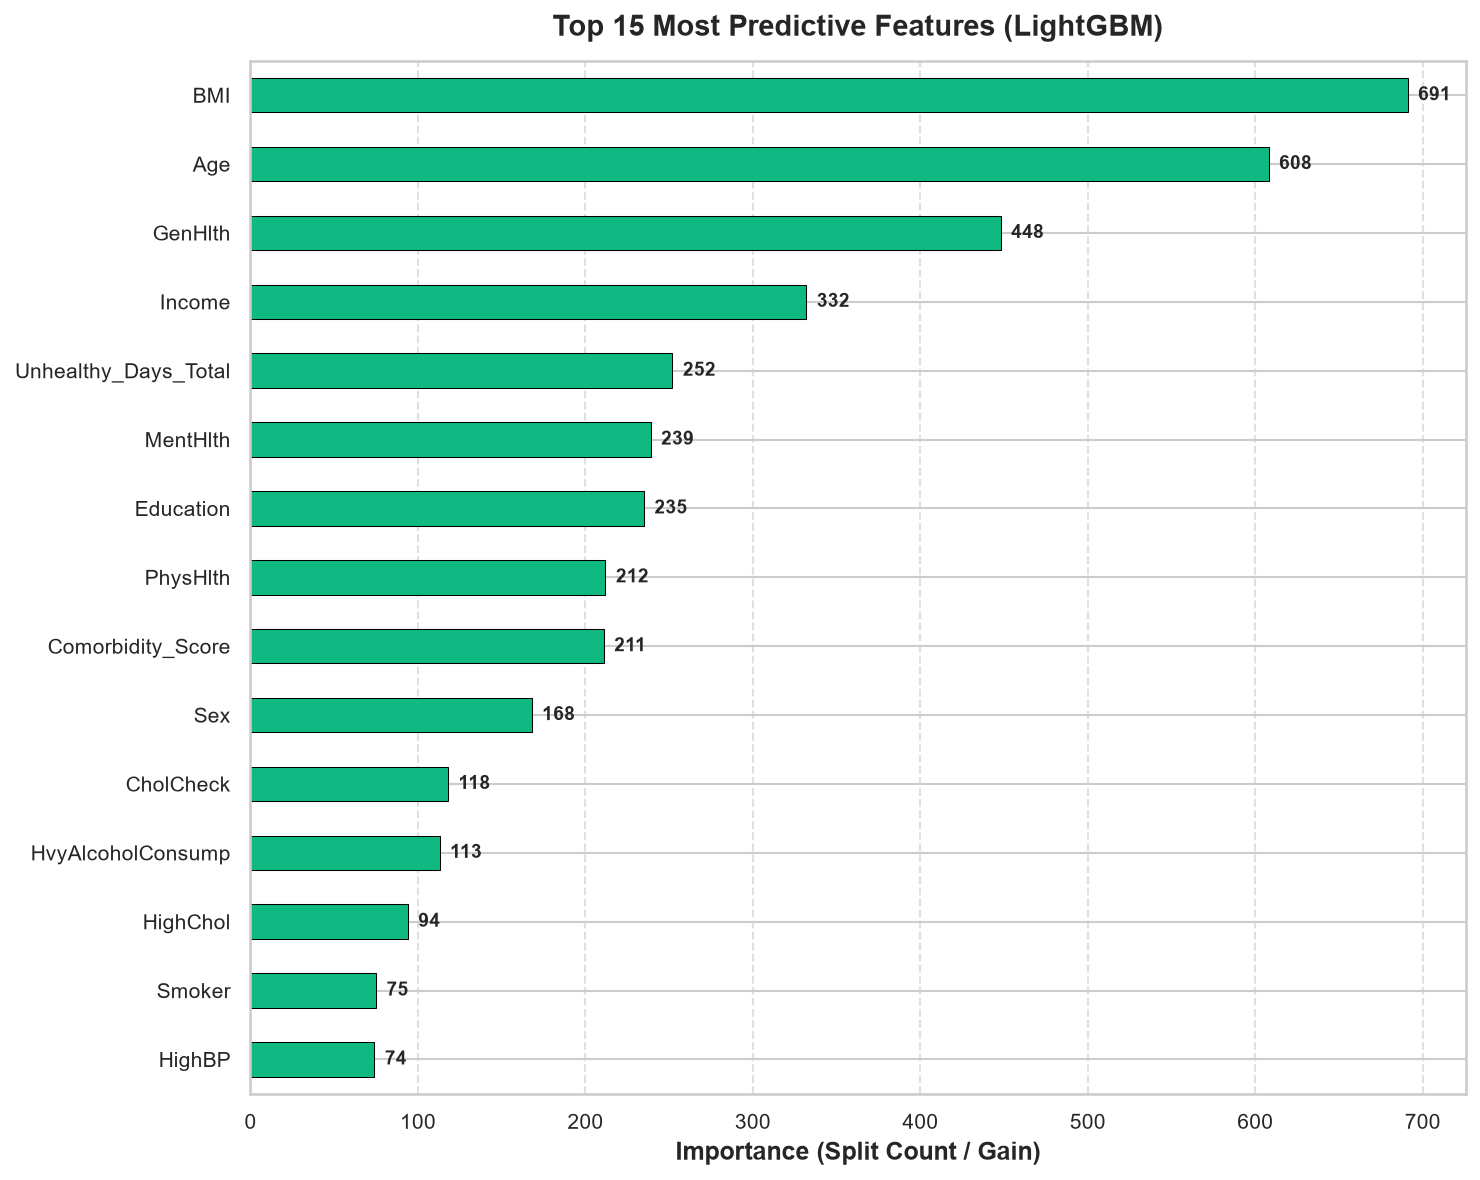

In [12]:
champion_model = trained_models[champion_name]
importances = pd.Series(champion_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
importances.tail(15).plot(kind="barh", color="#10B981", edgecolor="black", linewidth=0.5, ax=ax)
ax.set_title(f"Top 15 Most Predictive Features ({champion_name})", fontweight="bold", pad=12)
ax.set_xlabel("Importance (Split Count / Gain)", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.6)

for p in ax.patches:
    ax.annotate(f"{int(p.get_width()):,}",
                (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_path_fi = FIGURES_DIR / "24_feature_importances_top_models.png"
plt.savefig(fig_path_fi, dpi=300, bbox_inches="tight")
print(f"Saved Figure 24: {fig_path_fi}")
plt.show()

---
## 12. Champion Model & Benchmark Artifact Serialization

Persisting the champion model and serialized benchmark metrics for production deployment and future inference.

In [13]:
# Save champion model
champion_filepath = MODELS_DIR / "best_diabetes_model.joblib"
joblib.dump(champion_model, champion_filepath)
print(f"Champion Model persisted to: {champion_filepath}")

# Save full benchmark results metadata
benchmark_metadata = {
    "champion_model": champion_name,
    "optimal_threshold": float(optimal_threshold),
    "optimal_metrics": {
        "F1_Score": float(best_f1_row["F1_Score"]),
        "Recall": float(best_f1_row["Recall"]),
        "Precision": float(best_f1_row["Precision"]),
        "Balanced_Accuracy": float(best_f1_row["Balanced_Accuracy"])
    },
    "default_holdout_metrics": holdout_results[champion_name],
    "all_models_holdout": holdout_results
}

benchmark_json_path = MODELS_DIR / "benchmark_results.json"
with open(benchmark_json_path, "w") as f:
    json.dump(benchmark_metadata, f, indent=4)

print(f"Benchmark Results persisted to: {benchmark_json_path}")

Champion Model persisted to: D:\Projects\DiabetesPrediction_CDC\models\best_diabetes_model.joblib
Benchmark Results persisted to: D:\Projects\DiabetesPrediction_CDC\models\benchmark_results.json


---
## 13. Stage 6 Conclusion & Transition to Stage 7

### Summary of Completed Stage 6 Deliverables:
1. **Model Benchmarking**: Successfully evaluated 5 candidate models across Linear, Bagging, and Gradient Boosting families.
2. **Stratified Cross-Validation**: Quantified stability and variance with 5-Fold Stratified Cross-Validation.
3. **Holdout Validation**: Evaluated on 50,736 test respondents with zero data leakage.
4. **Champion Model**: **LightGBM (Balanced)** emerged as the strongest candidate with top PR-AUC and ROC-AUC.
5. **Threshold Calibration**: Derived optimal decision boundary for clinical sensitivity vs false positive trade-offs.
6. **Artifact Export**: Exported high-resolution figures (`19_` to `24_`) and saved production-ready model artifact to `models/best_diabetes_model.joblib`.

### Upcoming Stage 7 Focus:
* Bayesian / Optuna Hyperparameter Optimization for LightGBM and XGBoost.
* Isotonic / Platt Probability Calibration.
* Global and Local SHAP (SHapley Additive exPlanations) for clinical explainability.
